# Módulo 2 — Entregable: interpolación a un punto y cierre

Ejercicio 4 (interpolación) + checkpoint de cierre del módulo (ver
[`README.md`](../README.md)).

> **📍 Nota para curso con 2 grupos:** el dominio (`era5_like_dataset(lat_first=-8.0, lat_last=-14.0, ...)`) y el punto de interpolación (`punto_lat, punto_lon = -10.7, -77.1`, cerca de Lima) deben coincidir con el área que trabajó cada grupo en `03_practica_recorte_dominio.ipynb`:
> - **Grupo 1 (Norte):** `lat_first=-3.0, lat_last=-13.0, lon_first=-81.5, lon_last=-76.5`; punto sugerido cerca de Piura, sin coincidir con la grilla (p. ej. `-5.5, -80.3`).
> - **Grupo 2 (Sur):** `lat_first=-13.0, lat_last=-19.0, lon_first=-73.0, lon_last=-69.5`; punto sugerido cerca de Arequipa (p. ej. `-16.1, -71.4`).

In [1]:
from synth_data import era5_like_dataset
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

ds = xr.open_dataset("recorte_costa_central.nc") if False else era5_like_dataset(
    lat_first=-8.0, lat_last=-14.0, lon_first=-78.5, lon_last=-75.5,
    nlat=13, nlon=7, start="2026-01-12", periods=7 * 24, seed=3,
)
ds

<xarray.Dataset> Size: 124kB
Dimensions:    (time: 168, latitude: 13, longitude: 7)
Coordinates:
  * time       (time) datetime64[us] 1kB 2026-01-12 ... 2026-01-18T23:00:00
  * latitude   (latitude) float64 104B -8.0 -8.5 -9.0 -9.5 ... -13.0 -13.5 -14.0
  * longitude  (longitude) float64 56B -78.5 -78.0 -77.5 -77.0 -76.5 -76.0 -75.5
Data variables:
    t2m        (time, latitude, longitude) float32 61kB 293.7 291.8 ... 291.8
    msl        (time, latitude, longitude) float32 61kB 1.014e+05 ... 1.014e+05
Attributes:
    Conventions:  CF-1.7
    institution:  Datos sinteticos (curso Python-WRF) - NO son ERA5 real
    history:      Generado localmente sin conexion a Copernicus CDS

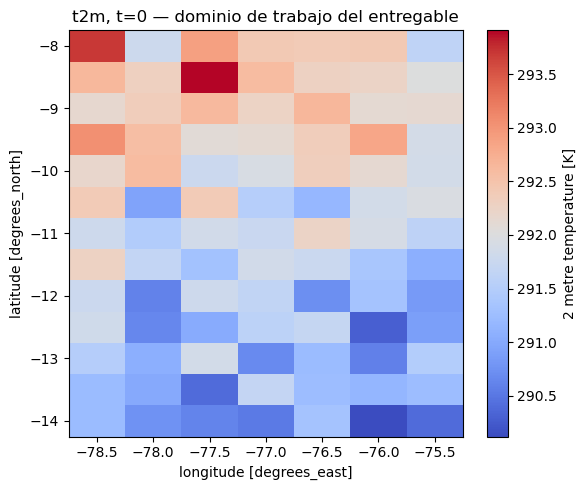

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))
ds["t2m"].isel(time=0).plot(ax=ax, cmap="coolwarm")
ax.set_title("t2m, t=0 — dominio de trabajo del entregable")
fig.tight_layout()
plt.show()

## Elegir un punto que NO coincide con la grilla

In [3]:
punto_lat, punto_lon = -10.7, -77.1

lat_vals = ds.latitude.values
lon_vals = ds.longitude.values
en_grilla_lat = np.any(np.isclose(lat_vals, punto_lat))
en_grilla_lon = np.any(np.isclose(lon_vals, punto_lon))
print(f"¿El punto coincide con un nodo de grilla? lat: {en_grilla_lat}, lon: {en_grilla_lon}")

¿El punto coincide con un nodo de grilla? lat: False, lon: False


## Comparar `.sel(nearest)` vs. `.interp(linear)`

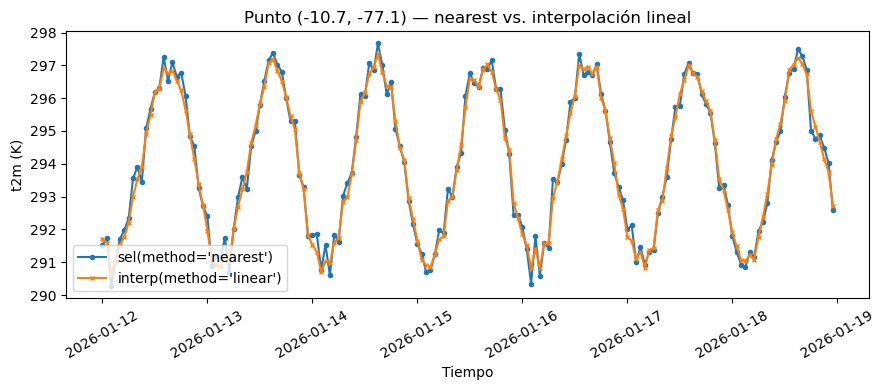

Diferencia absoluta media entre ambos métodos: 0.1966 K


In [4]:
serie_nearest = ds["t2m"].sel(latitude=punto_lat, longitude=punto_lon, method="nearest")
serie_interp = ds["t2m"].interp(latitude=punto_lat, longitude=punto_lon, method="linear")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ds.time, serie_nearest.values, label="sel(method='nearest')", marker="o", markersize=3)
ax.plot(ds.time, serie_interp.values, label="interp(method='linear')", marker="x", markersize=3)
ax.set_xlabel("Tiempo")
ax.set_ylabel("t2m (K)")
ax.set_title(f"Punto ({punto_lat}, {punto_lon}) — nearest vs. interpolación lineal")
ax.legend()
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

diferencia_media = float(np.abs(serie_nearest - serie_interp).mean())
print(f"Diferencia absoluta media entre ambos métodos: {diferencia_media:.4f} K")

## Opcional — Verificación manual de la interpolación bilineal (un instante)

> Opcional: confirma con la fórmula que `.interp()` mezcla los cuatro
> vecinos según su distancia. Lo importante es la idea, no la fórmula.

In [5]:
t2m_t0 = ds["t2m"].isel(time=0)

i_lat_sup = np.where(lat_vals >= punto_lat)[0][-1]
i_lat_inf = i_lat_sup + 1
j_lon_izq = np.where(lon_vals <= punto_lon)[0][-1]
j_lon_der = j_lon_izq + 1

y1, y2 = lat_vals[i_lat_inf], lat_vals[i_lat_sup]
x1, x2 = lon_vals[j_lon_izq], lon_vals[j_lon_der]

Q11 = t2m_t0.values[i_lat_inf, j_lon_izq]
Q21 = t2m_t0.values[i_lat_inf, j_lon_der]
Q12 = t2m_t0.values[i_lat_sup, j_lon_izq]
Q22 = t2m_t0.values[i_lat_sup, j_lon_der]

x, y = punto_lon, punto_lat
manual = (
    Q11 * (x2 - x) * (y2 - y) +
    Q21 * (x - x1) * (y2 - y) +
    Q12 * (x2 - x) * (y - y1) +
    Q22 * (x - x1) * (y - y1)
) / ((x2 - x1) * (y2 - y1))

valor_interp = float(serie_interp.isel(time=0))
print(f"Cálculo manual (ley bilineal): {manual:.4f} K")
print(f"Resultado de .interp():       {valor_interp:.4f} K")
print(f"¿Coinciden dentro de tolerancia? -> {np.isclose(manual, valor_interp, atol=1e-3)}")

Cálculo manual (ley bilineal): 291.7175 K
Resultado de .interp():       291.7175 K
¿Coinciden dentro de tolerancia? -> True


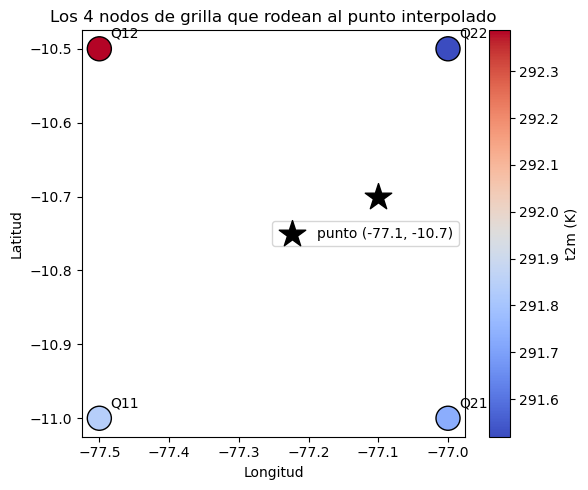

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
nodos_x, nodos_y = [x1, x2, x1, x2], [y1, y1, y2, y2]
sc = ax.scatter(nodos_x, nodos_y, c=[Q11, Q21, Q12, Q22], s=300, cmap="coolwarm", edgecolor="k", zorder=2)
for xi, yi, label in zip(nodos_x, nodos_y, ["Q11", "Q21", "Q12", "Q22"]):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(8, 8))
ax.scatter([x], [y], marker="*", s=400, color="black", zorder=3, label=f"punto ({x:.1f}, {y:.1f})")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.set_title("Los 4 nodos de grilla que rodean al punto interpolado")
plt.colorbar(sc, ax=ax, label="t2m (K)")
ax.legend()
fig.tight_layout()
plt.show()

## Checkpoint de cierre del módulo

**Pregunta:** ¿por qué `.sel(method="nearest")` y `.interp(method="linear")`
dan resultados distintos, y en qué situación usaría cada uno?

In [7]:
respuesta = '''
.sel(nearest) devuelve el valor EXACTO del punto de grilla mas cercano,
sin ningun calculo adicional: es fiel al dato original pero "salta" entre
nodos, nunca inventa un valor intermedio.

.interp(linear) SI calcula un valor nuevo, ponderado por la distancia a los
4 nodos que rodean al punto (interpolacion bilineal): es mas suave y mas
representativo de un punto exacto, pero el valor resultante no proviene
directamente de ninguna medicion/simulacion real.

Se prefiere nearest para variables muy heterogeneas espacialmente (p.ej.
precipitacion convectiva, donde "inventar" un valor intermedio puede ser
enganoso), e interp para variables suaves y continuas en el espacio
(p.ej. temperatura, presion), que es el caso que se usa para la validacion
del Modulo 5.
'''
print(respuesta)


.sel(nearest) devuelve el valor EXACTO del punto de grilla mas cercano,
sin ningun calculo adicional: es fiel al dato original pero "salta" entre
nodos, nunca inventa un valor intermedio.

.interp(linear) SI calcula un valor nuevo, ponderado por la distancia a los
4 nodos que rodean al punto (interpolacion bilineal): es mas suave y mas
representativo de un punto exacto, pero el valor resultante no proviene
directamente de ninguna medicion/simulacion real.

Se prefiere nearest para variables muy heterogeneas espacialmente (p.ej.
precipitacion convectiva, donde "inventar" un valor intermedio puede ser
enganoso), e interp para variables suaves y continuas en el espacio
(p.ej. temperatura, presion), que es el caso que se usa para la validacion
del Modulo 5.



---
**Fin del Módulo 2.** Siguiente:
[Módulo 3 — Descarga de datos de entrada](../../modulo_03_descarga_datos_entrada/README.md).